In [2]:
from netCDF4 import Dataset, num2date
import pandas as pd
import os
import glob
import numpy as np
from matplotlib import pyplot as plt
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
# from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import geopandas as gpd
import reliability_utils as ru
from shapely.geometry import box

# ISS LIS Data Sets

In [2]:
#Define the directory of the files
file_path = '/home/qsel/Desktop/data/lightning/'
dataDir = os.path.join(file_path, '') 

#Identify all the ISS LIS NetCDF files in the directory and their paths
raw_files = glob.glob(dataDir+'ISS_LIS_*.nc')
files = [os.path.normpath(i) for i in raw_files]    

#Extract the dates for the files
#Create empty lists to hold the orbit start and end times
orbit_start = []
orbit_end = []

#Define the directory of the files
dataDir = os.path.join(file_path, '') 

#Identify all the ISS LIS NetCDF files in the directory and their paths
raw_files = glob.glob(dataDir+'ISS_LIS_*.nc')
files = [os.path.normpath(i) for i in raw_files]    

#Extract the dates for the files
#Create empty lists to hold the orbit start and end times
orbit_start = []
orbit_end = []

#Loop through the NetCDF files and for each file, extract the start and end time of the ISS LIS
#orbit, adding them to the respective empty list (orbit_start and orbit_end)
for i in files:
    datafile = Dataset(i,'r')

    start_value = datafile.variables['orbit_summary_TAI93_start'][:].data.tolist()
    start_value_units = datafile.variables['orbit_summary_TAI93_start']
    end_value = datafile.variables['orbit_summary_TAI93_end'][:].data.tolist()
    end_value_units = datafile.variables['orbit_summary_TAI93_end']
    orbit_start.append(start_value)
    orbit_end.append(end_value)

#From the start and end times, calculate the minimum and maximum date of the files
start_dates = num2date(orbit_start[:], start_value_units.units)
stop_dates = num2date(orbit_end[:], end_value_units.units)

begin_date_value = min(start_dates)
end_date_value = max(stop_dates)

#Create text and numerical dates to use in file names and plot title
begin_date = begin_date_value.strftime("%B %d, %Y")
end_date = end_date_value.strftime("%B %d, %Y")
begin_int = begin_date_value.strftime("%Y%m%d")
end_int = end_date_value.strftime("%Y%m%d")



NameError: name 'start_value_units' is not defined

In [3]:
#Define the directory of the files
file_path = '/home/qsel/Desktop/data/lightning_2/'
dataDir = os.path.join(file_path, '') 

#Identify all the ISS LIS NetCDF files in the directory and their paths
raw_files = glob.glob(dataDir+'ISS_LIS_*.nc')
files = [os.path.normpath(i) for i in raw_files]   

#Extract lightning flash locations
#Create empty arrays to populate lightning flash location coordinates 
flash_lat = np.array([]) #latitude
flash_lon = np.array([]) #longitude
#Loop through list of NetCDF files and for each file, extract the lightning flash latidude
#and longitude, adding them to the respective empty array (flash_lat and flash_lon)
for i in files:
    
    datafile = Dataset(i)
    try:
        flash_lat = np.concatenate([flash_lat,datafile.variables['lightning_flash_lat'][:]]) #add to array
        flash_lon = np.concatenate([flash_lon,datafile.variables['lightning_flash_lon'][:]]) #add to array
        print(f'works: {i}')
    except:
        print(f'dont work: {i}')


dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20231001_161701_NRT.nc
works: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230928_213251_NRT.nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230918_065624_NRT.nc
works: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230921_122051_NRT.nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230927_085251_NRT.nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230924_213633_NRT.nc
works: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20231001_204650_NRT .nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230928_051830_NRT.nc
works: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230922_113053_NRT.nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230930_082251_NRT.nc
dont work: /home/qsel/Desktop/data/lightning_2/ISS_LIS_SC_V2.2_20230922_205051_NRT.nc


# TRMM (1998-2015)

In [2]:
#Define the directory of the files
# file_path = '/home/qsel/Desktop/data/lightning/TRMM'
file_path = '/home/qsel/Desktop/data/lightning/TRMM_2010_2015'
dataDir = os.path.join(file_path, '') 

#Identify all the ISS LIS NetCDF files in the directory and their paths
raw_files = glob.glob(dataDir+'TRMM_LIS_SC*.nc')
files = [os.path.normpath(i) for i in raw_files]   

#Extract lightning flash locations
#Create empty arrays to populate lightning flash location coordinates 
flash_lat = np.array([]) #latitude
flash_lon = np.array([]) #longitude
flash_radiance = np.array([]) # flash radiance 
#Loop through list of NetCDF files and for each file, extract the lightning flash latidude
#and longitude, adding them to the respective empty array (flash_lat and flash_lon)
m,n = 0,0
for i in files:
    
    datafile = Dataset(i)
    try:
        m = m+1
        flash_lat = np.concatenate([flash_lat,datafile.variables['lightning_flash_lat'][:]]) #add to array
        flash_lon = np.concatenate([flash_lon,datafile.variables['lightning_flash_lon'][:]]) #add to array
        flash_radiance = np.concatenate([flash_radiance,datafile.variables['lightning_flash_radiance'][:]]) #add to array
        # print(f'{m}: works: {i}')
    except:
        n = n+1
        print(f'{n}: dont work: {i}')



1: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.1_2013.039.86775.nc
2: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2015.061.98513.nc
3: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2014.301.96546.nc
4: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2014.125.93799.nc
5: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2015.076.98746.nc
6: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2014.337.97121.nc
7: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2015.010.97712.nc
8: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.1_2013.100.87721.nc
9: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.1_2013.034.86698.nc
10: dont work: /home/qsel/Desktop/data/lightning/TRMM_2010_2015/TRMM_LIS_SC.04.3_2015.004.97620.nc
11: dont work: /hom

# Select lightning flashes that fall in Rwanda bounding box

In [3]:
rwanda_lat = np.array([])
rwanda_lon = np.array([])
rwanda_rad = np.array([])
for lat,lon,rad in zip(flash_lat,flash_lon,flash_radiance): 
    if ((lat >= -2.91785776125)&(lat <= -1.13465911215)&(lon >= 29.0249263852)&(lon <= 30.8161348813)): # If value is bigger or equal to 5
        rwanda_lat = np.append(rwanda_lat, lat) # add to array
        rwanda_lon = np.append(rwanda_lon, lon) # add to array
        rwanda_rad = np.append(rwanda_rad, rad) # add to array

/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


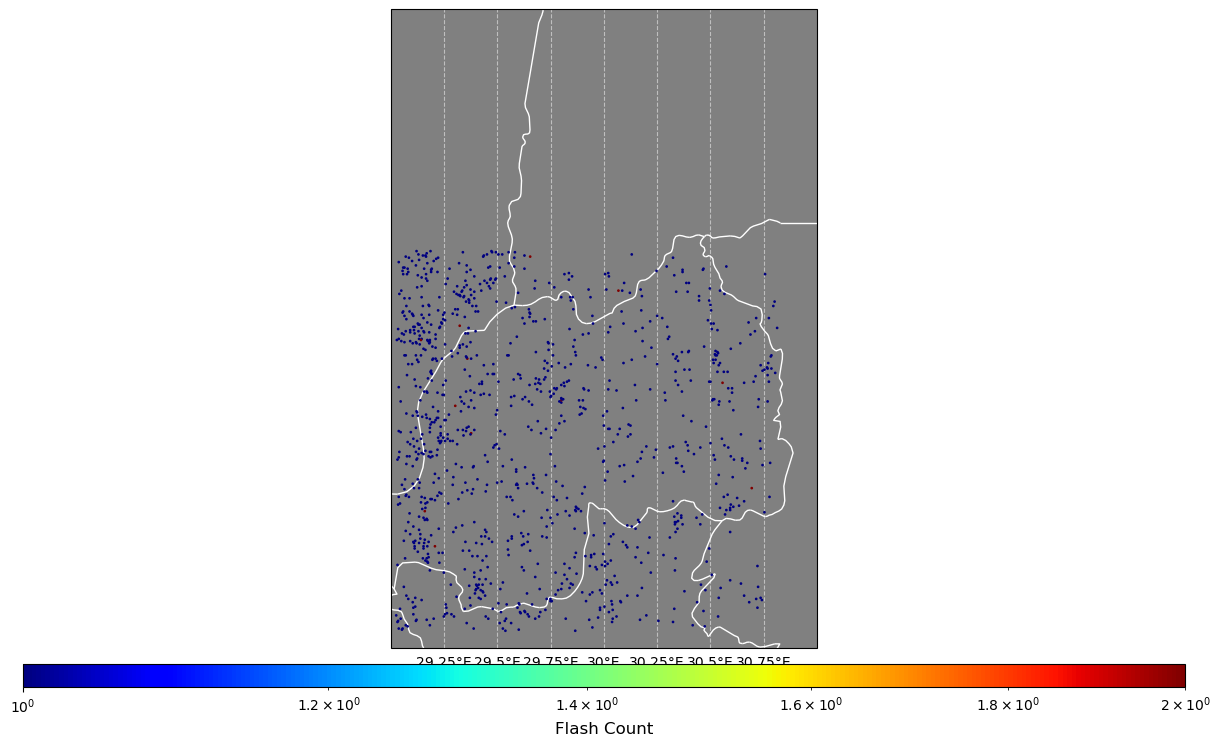

In [7]:
#Create plot of lightning flash location heat map
plt.figure(figsize=((15,10))) #Set plot dimensions
map = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0))
gl = map.gridlines(crs=ccrs.PlateCarree(central_longitude=0.0), draw_labels=True, linewidth=0.8, alpha=0.5, color='white', linestyle='--')
lightning = map.hexbin(rwanda_lon, rwanda_lat, gridsize=300, bins='log',cmap='jet', mincnt=1 ,zorder=10) #Bin flash counts into hexbins using a gridsize of your choice

#Draw geographic boundaries and meridians/parallels
# map.set_extent([-180, 180,-90, 90])
map.set_extent([29, 31,-3, 0])
map.coastlines(color='white')
map.add_feature(cfeature.LAND, facecolor='gray')
map.add_feature(cfeature.BORDERS, edgecolor='white')
map.add_feature(cfeature.OCEAN, facecolor='black')
gl.ylocator = mticker.FixedLocator([-90, -60, -30, 0 ,30, 60, 90])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabels_top=False
gl.ylabels_right=False

#Create colorbar
cbar = plt.colorbar(lightning, orientation='horizontal', pad=0.02, aspect=50) 
cbar.set_label('Flash Count', fontsize=12) #Remember to change label
    
# #Create plot title based on file dates
# if begin_date != end_date:
#     plot_title = 'ISS LIS Detected Lightning Flash Locations ' + begin_date + ' - ' + end_date
# else:
#     plot_title = 'ISS LIS Detected Lightning Flash Locations ' + end_date

# plt.title(plot_title, fontsize = 18) 


### Save file

In [9]:
df.to_csv('../data/processed/lightning_locations.csv',index=False)

# Create Lightning dataframe

In [4]:
# Define Projection 
project_crs = 'epsg:32735'
geo_crs = 'epsg:4326'

# load datasets
# dir_path = '~/Desktop/data/REG_Tariffs/LV_lines/'
dir_path = '../data/raw/LV_lines/'
lines = gpd.read_file(dir_path+'lv_lines.shp')
clean_lines,feeder_bboxs_gdf =  ru.clean_lines(lines)


# district borders
# dir_path = '/home/qsel/Desktop/data/consumption_data/'
dir_path = '../data/raw/'
districts = gpd.read_file(dir_path+'District_Boundaries.geojson')
# districts = districts.to_crs(project_crs)
districts['district'] = districts['district'].str.lower() # convert to lower Villages_boundaries

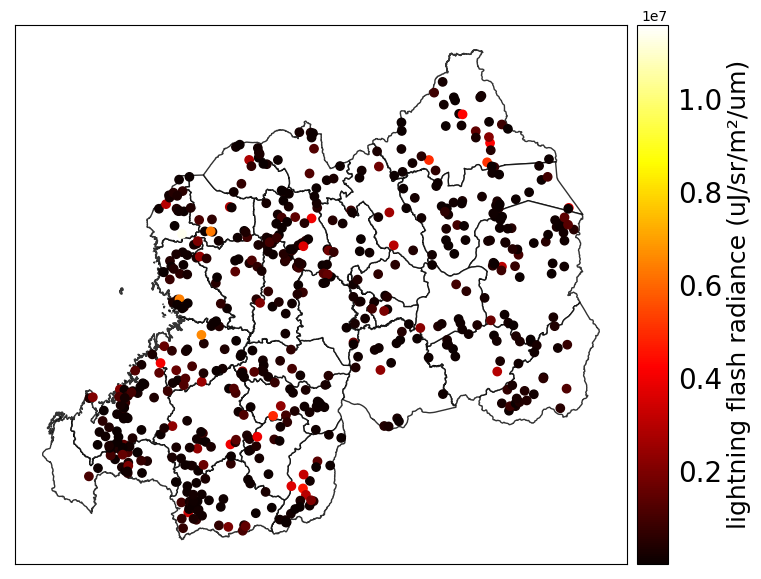

In [11]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
# creating lightning dataframe
# df = pd.DataFrame({ "latitude": rwanda_lat,"longitude": rwanda_lon,"radiance":rwanda_rad,})
df = pd.read_csv('../data/processed/lightning_locations.csv')
lightning_gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326"
)
# remove lightning points that don't fall within the country
lightning_points_rwanda = gpd.sjoin(lightning_gdf, districts[['geometry']], how="inner", predicate="within").drop(columns='index_right')

# plot of location of lightning strikes
fontsize=28
tckfz = 20
fig, ax = plt.subplots(1, figsize = (15, 7))
# create `cax` for the colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
districts.plot(ax=ax,alpha=0.8,edgecolor='black',color='white') 
# feeder_bboxs_gdf.plot(ax=ax,alpha=0.6,edgecolor='black',color='white') 
lightning_points_rwanda.plot(ax=ax,column='radiance',legend=True, cmap='hot',cax=cax)
cb_ax = fig.axes[1] 
cb_ax.tick_params(labelsize=tckfz)
plt.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')

# manipulate the colorbar `cax`
cax.set_ylabel('lightning flash radiance (uJ/sr/m²/um)', rotation=90,fontsize=18)

plt.show()

In [21]:
feeder_means = []
feeder_counts = []
feeder_maximums = []
for i in range(0,len(feeder_bboxs_gdf)):
    radiance_list = lightning_points_rwanda[lightning_points_rwanda.geometry.intersects(feeder_bboxs_gdf.geometry.iloc[i])].radiance.tolist()
    if not radiance_list:
        feeder_means.append(np.nan)
        feeder_counts.append(np.nan)
        feeder_maximums.append(np.nan)
    else:
        feeder_means.append(np.nanmean(radiance_list))
        feeder_counts.append(len(radiance_list))
        feeder_maximums.append(np.max(radiance_list))
feeder_bboxs_gdf['IV_feeder_lightning_means'] = feeder_means
feeder_bboxs_gdf['IV_feeder_lightning_counts'] = feeder_counts
feeder_bboxs_gdf['IV_feeder_lightning_maximums'] = feeder_maximums

In [26]:
feeder_bboxs_gdf.drop(columns='geometry').to_csv('../data/processed/IV_feeder_lightning_metrics.csv',index=False)